# Time-dependent continuum spectra under microlensing

This tutorial keeps the quasar fixed on the sky while the microlenses move. It follows the observed-frame continuum from 3000 to 11000 Angstrom in 20 Angstrom steps and builds two demonstrations:

1. a controlled one-star-plus-shear field that moves two folds across the stationary disk, and
2. the full, kinematically evolving Q2237+0305 image-B-like stellar realization used by the production tutorials.

For each field we generate one microlensing-plus-intrinsic-variability GIF. The microlensing-only calculation is retained as the dashed comparison baseline rather than exported as a second animation. Magnification maps evolve every 25 days. The intrinsic lamp-driven disk and its six LSST effective-wavelength light curves are evaluated daily. The dense continuum spectra are evaluated at the 25-day map epochs.

The spectral axis always shows **observed wavelength**. Values are monochromatic observed-frame $F_\nu$ in Jy, not throughput-integrated filters. The continuum model contains no emission lines, absorption, or intergalactic attenuation.

GIF previews are embedded below. If needed, only their duration is shortened,
keeping the original resolution, cadence, and playback speed. The full GIFs
are generated by this notebook and linked below each animation.


In [1]:
from pathlib import Path

import warnings
import numpy as np
import torch
from matplotlib import pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from IPython.display import Image, display

import microcaustics as mc
import microcaustics.plotting as mcp

plt.rcParams.update(mcp.publication_style())
OUTPUT_DIRECTORY = Path("spectral_microlensing_output")
OUTPUT_DIRECTORY.mkdir(exist_ok=True)

capabilities = mc.RuntimeCapabilities.detect()
use_cuda = capabilities.cuda_available and capabilities.triton_importable
runtime_config = mc.RuntimeConfig(
    device="cuda" if use_cuda else "cpu",
    backend="triton" if use_cuda else "auto",
    dtype=torch.float32,
    strict_backend=use_cuda,
    memory_fraction=0.95,
)
runtime = mc.resolve_runtime(runtime_config)

# Production is the notebook default on every machine. There is no automatic
# CPU downgrade: a missing CUDA runtime may make execution slow, but it can no
# longer silently replace the scientific output with a short coarse smoke run.
WAVELENGTH_STEP_ANGSTROM = 20.0
SOURCE_RESOLUTION = 512
MAP_RESOLUTION = 1024
SIMPLE_DURATION_DAYS = 3650.0
Q2237_DURATION_DAYS = 3650.0
MAP_CADENCE_DAYS = 25.0
SOURCE_CADENCE_DAYS = 1.0
SIMPLE_RAYS = 10_000_000
Q2237_RAYS = 10_000_000
FPS = 8

if not use_cuda:
    warnings.warn(
        "CUDA/Triton is unavailable. Production dimensions and 10^7-ray IPM "
        "remain active; use the package CUDA environment before executing the "
        "full notebook.",
        RuntimeWarning,
    )

print(mcp.runtime_description())
print("Observed spectral spacing [Angstrom]:", WAVELENGTH_STEP_ANGSTROM)
print("Disk brightness resolution:", SOURCE_RESOLUTION)
print("Magnification-map resolution:", MAP_RESOLUTION)
print("Duration [days]:", Q2237_DURATION_DAYS)
print("Photometry/map cadence [days]:", SOURCE_CADENCE_DAYS, MAP_CADENCE_DAYS)
GIF_DIRECTORY = Path("../assets/animations")
GIF_DIRECTORY.mkdir(parents=True, exist_ok=True)


Python 3.11.15 | PyTorch 2.12.1+cu130 | Windows AMD64 | CUDA 13.0, NVIDIA GeForce RTX 5070 Ti, compute capability 12.0
Observed spectral spacing [Angstrom]: 20.0
Disk brightness resolution: 512
Magnification-map resolution: 1024
Duration [days]: 3650.0
Photometry/map cadence [days]: 1.0 25.0


## Q2237-sized relativistic continuum source

The black-hole mass, accretion rate, spin, inclination, lamp geometry, redshifts, and choice of source extent match the Q2237 production tutorial. Thus both the controlled and full-field examples use a physically sized disk rather than an arbitrary Gaussian source.

The Kerr observer transfer is achromatic, so the same radius, redshift, solid-angle, and delay arrays support both the dense wavelength grid and the six LSST effective wavelengths. The system can also hold the driver at its mean without constructing a second source by hand.

In [2]:
lens_redshift, source_redshift = 0.0395, 1.695
H0, Om0 = 70.0, 0.3
black_hole_mass_solar = 10.0**9.08

wavelengths = np.arange(
    3000.0, 11000.0 + 0.5 * WAVELENGTH_STEP_ANGSTROM,
    WAVELENGTH_STEP_ANGSTROM,
)
spectral_bands = {f"lambda_{int(value):05d}": float(value) for value in wavelengths}
lsst_bands = {
    "u": 3671.0, "g": 4827.0, "r": 6223.0,
    "i": 7546.0, "z": 8691.0, "y": 9712.0,
}

driver = mc.broken_power_law_driving_signal(
    cadence_days=SOURCE_CADENCE_DAYS,
    max_duration_days=Q2237_DURATION_DAYS,
    history_days=1000.0,
    break_timescale_days=200.0,
    alpha_L=1.0,
    alpha_R=3.0,
    standard_deviation=0.10,
    seed=0,
)

disk_model = mc.KerrDiskModel(
    black_hole_mass_solar=black_hole_mass_solar,
    eddington_ratio=0.34,
    bands_angstrom=spectral_bands,
    spin=0.74,
    inclination_deg=10.0,
    position_angle_deg=0.0,
    lamp_fraction=0.1,
    corona_height_above_isco_rg=20.0,
    driving_signal=driver,
    source_grid_shape=SOURCE_RESOLUTION,
    enclosed_flux_fraction=0.999,
    source_margin=1.05,
    compile_solver=use_cuda,
    lamppost_nalpha=1024,
    lamppost_radial_bins=512,
)

q2237_macro = mc.MacroLens(
    convergence=0.391, shear=0.391, shear_angle_deg=141.73,
    smooth_matter_fraction=0.0,
)
q2237_population = mc.StellarPopulation.salpeter(
    mean_mass_solar=0.3, mass_ratio=100.0,
    kinematics=mc.SkyProjectedKinematics(
        ra_deg=340.126125, dec_deg=3.358611,
        stellar_dispersion_km_s=170.0,
        peculiar_velocity_dispersion_km_s=235.0,
        include_cmb_dipole=True, seed=0,
    ),
)
q2237_system = mc.MicrolensingSystem(
    lens_redshift=lens_redshift, source_redshift=source_redshift,
    H0=H0, Om0=Om0, macro=q2237_macro, source=disk_model,
    map_grid_shape=MAP_RESOLUTION, stellar_population=q2237_population,
    duration_days=Q2237_DURATION_DAYS, light_loss=0.01, safety_scale=1.5,
    seed=11, runtime=runtime_config,
)
q2237_realization = q2237_system.realize()
source_grid = q2237_realization.source_grid
source_fov_uas = source_grid.field_of_view_uas

driver_cadence_days = driver.metadata()["cadence_days"]
assert driver_cadence_days == SOURCE_CADENCE_DAYS
print("Intrinsic driver cadence [days]:", driver_cadence_days)
print("Observed wavelength channels:", len(wavelengths))
print("Observed wavelength range [Angstrom]:", wavelengths[[0, -1]])
print("Rest-frame range [Angstrom]:", wavelengths[[0, -1]] / (1.0 + source_redshift))
print("Q2237 disk field [microarcsec]:", source_fov_uas)

C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\relativity\primary.py:223: CompilationWarning: Compilation event 1: preparing a new torch.compile specialization for primary Kerr ray tracing on cuda:0 (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  calculation, execution = _primary_calculation(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\relativity\coordinates.py:1158: CompilationWarning: Compilation event 2: preparing a new torch.compile specialization for Kerr observer coordinates on cuda:0 (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  solver, execution = _coordinate_solver(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\relativity\lamppost.py:625: CompilationWarning: Compilation event 3: preparing a new torch.compile specialization for axis-lamppost ray tracing on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  rays = trace_axis_lamppost(


Intrinsic driver cadence [days]: 1.0
Observed wavelength channels: 401
Observed wavelength range [Angstrom]: [ 3000. 11000.]
Rest-frame range [Angstrom]: [1113.17254174 4081.63265306]
Q2237 disk field [microarcsec]: (11.048290285054495, 11.048290285054495)


## Static, unlensed observed continuum

The continuum is first integrated without either microlensing or stochastic variability. Colored markers identify the observed effective wavelengths used for the six LSST light curves below.

C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\transferred_disk.py:214: CompilationWarning: Compilation event 4: preparing a new torch.compile specialization for thermal spectral photometry on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  result, _ = run_tensor_kernel(


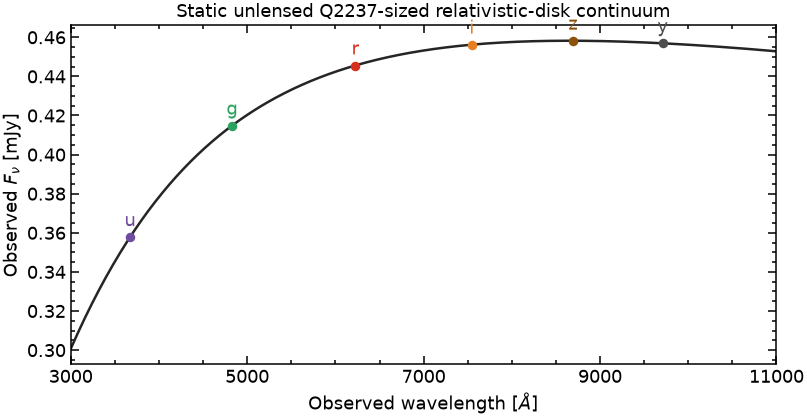

Wrote spectral_microlensing_output\static_unlensed_observed_continuum.png


In [3]:
static_unlensed_spectrum = q2237_system.source_light_curve(
    [0.0], apply_driving_signal=False, band_batch_size=32,
).flux[0].detach().cpu().numpy()

colors = mcp.band_colors(tuple(lsst_bands))
lsst_wave_array = np.asarray(list(lsst_bands.values()))
static_lsst_flux = np.interp(lsst_wave_array, wavelengths, static_unlensed_spectrum)

figure, axis = plt.subplots(figsize=(8.4, 4.5))
axis.plot(wavelengths, 1.0e3 * static_unlensed_spectrum, color="#252525", lw=1.8)
for (band, wave), flux in zip(lsst_bands.items(), static_lsst_flux):
    axis.scatter(wave, 1.0e3 * flux, color=colors[band], s=34, zorder=3)
    axis.annotate(band, (wave, 1.0e3 * flux), xytext=(0, 8), textcoords="offset points", ha="center", color=colors[band])
axis.set(
    xlabel=r"Observed wavelength [$\AA$]",
    ylabel=r"Observed $F_\nu$ [mJy]",
    title="Static unlensed Q2237-sized relativistic-disk continuum",
    xlim=(3000.0, 11000.0),
)
axis.set_xticks([3000, 5000, 7000, 9000, 11000])
mcp.finish_axis(axis)
figure.tight_layout()
static_path = OUTPUT_DIRECTORY / "static_unlensed_observed_continuum.png"
figure.savefig(static_path, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
print("Wrote", static_path)

## Shared helpers: daily light curves and 25-day spectra

`MicrolensingSystem.light_curves` produces the variable and mean-driver products from one source and one shared map sequence. Both six-band light curves use daily photometry, while the spectra use the 25-day map epochs.

The same call treats the 401 observed wavelengths as ordinary light-curve bands. `band_batch_size=32` bounds source memory. The final partial wavelength batch is padded internally to avoid an extra compiled shape and trimmed from the returned arrays. The source trajectory is never changed: its center remains at $(0,0)$ throughout.

In [4]:
def run_shared_light_curves(system, map_times, method, schedule):
    variable_curve, static_curve, variable_spectrum, static_spectrum = system.light_curves(
        map_times,
        requests=(
            mc.LightCurveRequest(
                name="variable", bands_angstrom=lsst_bands,
                flux_cadence_days=SOURCE_CADENCE_DAYS,
            ),
            mc.LightCurveRequest(
                name="microlensing-only", bands_angstrom=lsst_bands,
                flux_cadence_days=SOURCE_CADENCE_DAYS, apply_driving_signal=False,
            ),
            mc.LightCurveRequest(name="spectrum", bands_angstrom=spectral_bands),
            mc.LightCurveRequest(
                name="mean-spectrum", bands_angstrom=spectral_bands,
                apply_driving_signal=False,
            ),
        ),
        method=method,
        schedule=schedule,
        keep_maps_at_days=map_times,
        band_batch_size=32,
    )
    retained_maps = variable_curve.maps
    if len(retained_maps) != len(map_times):
        raise RuntimeError("shared light curves did not retain every map epoch")
    if any(left is not right for left, right in zip(
        retained_maps, static_curve.maps, strict=True,
    )):
        raise RuntimeError("shared light curves returned different retained maps")
    spectra = {
        "static_unlensed": static_spectrum.unlensed_flux.detach().cpu().numpy(),
        "static_lensed": static_spectrum.flux.detach().cpu().numpy(),
        "variable_unlensed": variable_spectrum.unlensed_flux.detach().cpu().numpy(),
        "variable_lensed": variable_spectrum.flux.detach().cpu().numpy(),
    }
    return variable_curve, static_curve, retained_maps, spectra


def magnitude_numpy(flux):
    return mc.flux_to_magnitude(flux).detach().cpu().numpy()


def report_intrinsic_variability(variable_curve, static_curve, label):
    variable_mag = magnitude_numpy(variable_curve.unlensed_flux.detach().cpu().numpy())
    static_mag = magnitude_numpy(static_curve.unlensed_flux.detach().cpu().numpy())
    difference = variable_mag - static_mag
    rms = np.std(difference, axis=0)
    peak_to_peak = np.ptp(difference, axis=0)
    print(label, "intrinsic RMS [mag]:", dict(zip(lsst_bands, np.round(rms, 4))))
    print(label, "intrinsic peak-to-peak [mag]:", dict(zip(lsst_bands, np.round(peak_to_peak, 4))))


# Measure the actual non-circular 95%-flux isophote of each time-averaged
# two-dimensional disk image. R_95 is only the area-equivalent sqrt(A/pi).
contour_wavelengths = np.asarray([3000.0, 5000.0, 7000.0, 9000.0, 11000.0])
contour_colors = ("#5e4fa2", "#3288bd", "#66c2a5", "#fdae61", "#d53e4f")
contour_bands = {
    f"lambda_{int(value):05d}": float(value) for value in contour_wavelengths
}
variable_contour_source = q2237_realization.source.with_bands(contour_bands)
contour_average_times = torch.arange(
    0.0, Q2237_DURATION_DAYS + 0.5 * SOURCE_CADENCE_DAYS,
    SOURCE_CADENCE_DAYS, device=runtime.device, dtype=runtime.dtype,
)
contour_summary = mcp.mean_source_isophotes(
    variable_contour_source,
    contour_average_times,
    source_grid,
    fraction=0.95,
    batch_size=8,
    dtype=runtime.dtype,
    device=runtime.device,
)
contour_images = contour_summary.images
contour_levels = contour_summary.levels
contour_r95_uas = contour_summary.area_equivalent_radii_uas
contour_enclosed_fractions = contour_summary.enclosed_fractions
source_x, source_y = contour_summary.x_uas, contour_summary.y_uas
sx0, sx1, sy0, sy1 = source_grid.bounds_uas
assert np.all(np.diff(contour_r95_uas) > 0.0)
assert np.allclose(contour_enclosed_fractions, 0.95, atol=2.0e-3)
print("Mean daily 95%-flux disk contours:")
for wave, radius, fraction in zip(
    contour_wavelengths, contour_r95_uas,
    contour_enclosed_fractions, strict=True,
):
    print(f"  {wave:5.0f} Angstrom: R_95={radius:.4f} uas, enclosed={fraction:.5f}")


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\reprocessing.py:553: CompilationWarning: Compilation event 5: preparing a new torch.compile specialization for retarded thermal driving on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  temperature4, _ = run_tensor_kernel(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\transferred_disk.py:163: CompilationWarning: Compilation event 6: preparing a new torch.compile specialization for relativistic disk brightness on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  brightness, _ = run_tensor_kernel(


Mean daily 95%-flux disk contours:
   3000 Angstrom: R_95=0.4593 uas, enclosed=0.95004
   5000 Angstrom: R_95=0.8262 uas, enclosed=0.95001
   7000 Angstrom: R_95=1.2442 uas, enclosed=0.95000
   9000 Angstrom: R_95=1.7006 uas, enclosed=0.95000
  11000 Angstrom: R_95=2.1950 uas, enclosed=0.95000


## Controlled crossing with one physically moving Q2237 star

The disk remains centered at the origin. The star velocity is one deterministic draw from the same Q2237 sky-projected kinematics used by the full population: bulk observer/lens/source motion plus a 170 km/s stellar velocity component. We initialize the star so that an off-cusp fold reaches the source center near the middle of the ten-year interval. No velocity is accelerated for presentation. A modest external shear of 0.10 keeps this controlled Chang–Refsdal caustic compact. The star retains the realistic 0.3-solar-mass Q2237 population mean.

The five colored boundaries are the actual non-circular 95%-flux isophotes of the disk at 3000, 5000, 7000, 9000, and 11000 Angstrom observed. Each image is averaged over the full daily variability sequence before its contour is measured. The legend reports the area-equivalent $R_{95}=\sqrt{A/\pi}$, but the plotted line retains the source image's true projected shape. No circular radius overlays are drawn.


In [5]:
simple_map_times = torch.arange(
    0.0, SIMPLE_DURATION_DAYS + 0.5 * MAP_CADENCE_DAYS, MAP_CADENCE_DAYS,
    dtype=torch.float32,
)
theta_e_uas = float(mc.einstein_radius_uas(
    0.3, lens_redshift=lens_redshift, source_redshift=source_redshift,
    H0=H0, Om0=Om0, device="cpu", dtype=torch.float32,
))

q2237_kinematics = mc.SkyProjectedKinematics(
    ra_deg=340.126125,
    dec_deg=3.358611,
    stellar_dispersion_km_s=170.0,
    peculiar_velocity_dispersion_km_s=235.0,
    include_cmb_dipole=True,
    lens_redshift=lens_redshift,
    source_redshift=source_redshift,
    seed=0,
)
motion = q2237_kinematics.resolved_metadata(q2237_system.distances)
bulk_velocity = np.asarray(motion["bulk_velocity_uas_per_day"], dtype=float)
stellar_sigma = float(motion["stellar_component_dispersion_uas_per_day"])
# A fixed one-star draw, in observer-frame east/north components.
star_velocity = bulk_velocity + stellar_sigma * np.asarray([0.8, -0.4])

gamma = 0.10
# This off-cusp fold coordinate was recovered from the centered one-star field.
fold_offset = theta_e_uas * np.asarray([0.145, 0.060])
# Translating the star by x_* translates the caustic by A x_*, where
# A=diag(1-gamma, 1+gamma) for this shear orientation.
star_at_midpoint = np.asarray([
    -fold_offset[0] / (1.0 - gamma),
    -fold_offset[1] / (1.0 + gamma),
])
star_initial = star_at_midpoint - star_velocity * (0.5 * SIMPLE_DURATION_DAYS)

simple_stars = mc.PointMassField(
    torch.tensor([star_initial[0]], dtype=torch.float32),
    torch.tensor([star_initial[1]], dtype=torch.float32),
    mass_solar=torch.tensor([0.3]),
    velocity_x_uas_per_day=torch.tensor([star_velocity[0]], dtype=torch.float32),
    velocity_y_uas_per_day=torch.tensor([star_velocity[1]], dtype=torch.float32),
)
simple_system = mc.MicrolensingSystem(
    macro=mc.MacroLens(convergence=0.0, shear=gamma, shear_angle_deg=0.0),
    lens_redshift=lens_redshift, source_redshift=source_redshift, H0=H0, Om0=Om0,
    stars=simple_stars,
    source=disk_model,
    map_grid_shape=MAP_RESOLUTION,
    lens_region=mc.PlaneRegion((16.0 * theta_e_uas, 16.0 * theta_e_uas)),
    duration_days=SIMPLE_DURATION_DAYS,
    runtime=runtime_config,
)
simple_method = mc.production_ipm_config(rays=SIMPLE_RAYS)
simple_schedule = mc.production_dynamic_config()
assert simple_method.rays == 10_000_000
assert simple_method.scout_ratio == 2
assert simple_method.refinement == 2
assert simple_method.virtual_refinement == 4
assert simple_schedule.temporal_batch_size == 49
assert simple_schedule.scout_refresh_frames == 10
# The explicit velocity already contains the Q2237 bulk term and one
# independent stellar draw, so the generic explicit-field warning does not
# apply to this deliberately constructed one-star example.
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore", category=mc.IncompleteKinematicsWarning,
        message="Dynamic explicit point-mass velocities omit.*",
    )
    simple_variable_curve, simple_static_curve, simple_maps, simple_spectra = run_shared_light_curves(
        simple_system, simple_map_times,
        simple_method, simple_schedule,
    )

simple_lens_grid = mc.PlaneGrid(
    (513 if use_cuda else 257,) * 2,
    (16.0 * theta_e_uas, 16.0 * theta_e_uas),
)
simple_simulation = simple_system.realize().simulation
simple_caustics = [
    simple_simulation.caustics(
        simple_lens_grid, time_days=float(time),
    ).caustic_segments_uas.detach().cpu().numpy()
    for time in simple_map_times
]
assert float(simple_variable_curve.times_days[1] - simple_variable_curve.times_days[0]) == SOURCE_CADENCE_DAYS
assert simple_maps[0].values.shape == (MAP_RESOLUTION, MAP_RESOLUTION)
print("Controlled IPM preset:", simple_method)
print("Controlled dynamic preset:", simple_schedule)
print("Controlled map epochs:", len(simple_map_times))
print("Controlled daily epochs:", len(simple_variable_curve.times_days))
print("Physical star velocity [microarcsec/day]:", star_velocity)
print("Star displacement over simulated baseline [microarcsec]:", star_velocity * SIMPLE_DURATION_DAYS)
print("Source center is fixed at (0, 0) microarcsec")
report_intrinsic_variability(simple_variable_curve, simple_static_curve, "Controlled field")

C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\ipm.py:902: CompilationWarning: Compilation event 7: preparing a new Triton specialization for IPM rasterization on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  _warn_new_triton_ipm_specialization(
C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\ipm.py:1291: CompilationWarning: Compilation event 8: preparing a new Triton specialization for batched IPM rasterization on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  _warn_new_triton_ipm_specialization(


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\sources\transferred_disk.py:209: CompilationWarning: Compilation event 9: preparing a new Triton specialization for thermal spectral photometry on cuda:0 (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  fast_result = triton_thermal_flux(left, right, fraction, arguments, runtime)


C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\direct.py:310: CompilationWarning: Compilation event 10: preparing a new torch.compile specialization for direct Jacobian block on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  (chunk_xx, chunk_xy), used = run_tensor_kernel(
C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\solvers\direct.py:195: CompilationWarning: Compilation event 11: preparing a new torch.compile specialization for direct deflection block on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  (chunk_alpha_x, chunk_alpha_y)

Controlled IPM preset: IPMConfig(rays=10000000, scout_ratio=2, refinement=2, virtual_refinement=4, tiled=True, scout_halo_pixels=0.0, scout_dilation_cells=1, scout_trace_centers=False, dual_scout_scalar_correction=True, cell_chunk_size=524288, compact_sparse_nodes=True, far_field_approx=FarFieldApproxConfig(enabled=True, cells_per_axis=16, nodes_per_cell_axis=8, exact_radius_cells=1.0, taylor_order=4, center_translation_order=10))
Controlled dynamic preset: DynamicConfig(temporal_batch_size=49, light_curve_batch_size=None, fused_temporal_ipm=True, scout_refresh_frames=10, tuning=AutoTuningConfig(enabled=False, tune_temporal_batch=True, tune_spatial_chunk=True, temporal_candidates=(1, 4, 8, 12, 16, 20, 24, 32, 40, 49, 64), spatial_candidates=(16384, 32768, 65536, 131072, 262144, 524288, 1048576), warmup_runs=1, benchmark_runs=2, maximum_trial_frames=64, memory_fraction=None, memory_headroom_fraction=0.95, verify_numerics=True, verification_rtol=5e-05, verification_atol=5e-06, cache=True

## Animation renderer

The panels do not overlap:

- upper left: a production-resolution evolving magnification map with fixed, time-averaged 95%-flux wavelength isophotes.
- upper right: observed continuum spectrum on exactly 3000–11000 Angstrom.
- middle right: chromatic magnification $\mu(\lambda)$ on its own axis.
- bottom: six LSST light curves in the style of `04_simulation_datasets`.

Solid colored lines show microlensing plus intrinsic variability and dashed colored lines show the corresponding microlensing-only baseline. Both are evaluated on the same one-day observer-time grid, so the intrinsic fluctuations are visible directly rather than displaced onto a separate magnitude baseline. The vertical dashed line marks the displayed map epoch, and the legend is placed in the upper-right corner of the light-curve panel.

Running the notebook writes both full ten-year GIFs. The embedded previews show
the controlled crossing at days 1000–2600 and Q2237 at days 1700–3300,
each at the original 25-day cadence.


In [6]:
def render_case(
    prefix, title, map_times, flux_times, maps, spectra,
    variable_curve, static_curve, *, caustics=None,
):
    map_times_np = map_times.detach().cpu().numpy()
    flux_times_np = flux_times.detach().cpu().numpy()
    log_maps = np.stack([
        torch.log10(item.values.clamp_min(1.0e-2)).detach().cpu().numpy()
        for item in maps
    ])
    finite_maps = log_maps[np.isfinite(log_maps)]
    map_limits = (
        float(np.nanpercentile(finite_maps, 0.2)),
        float(np.nanpercentile(finite_maps, 99.8)),
    )

    variable_lensed_mag = magnitude_numpy(variable_curve.flux.detach().cpu().numpy())
    static_lensed_mag_daily = magnitude_numpy(static_curve.flux.detach().cpu().numpy())
    map_indices = np.searchsorted(flux_times_np, map_times_np)
    static_lensed_mag = static_lensed_mag_daily[map_indices]

    band_handles = [
        Line2D([0], [0], color=colors[band], lw=1.8, label=band)
        for band in lsst_bands
    ]
    unlensed_spectra = spectra["variable_unlensed"]
    lensed_spectra = spectra["variable_lensed"]
    curve_times = flux_times_np
    lensed_mag = variable_lensed_mag
    baseline_mag = static_lensed_mag_daily
    suffix = "microlensing_and_variability"
    state_title = "Microlensing + intrinsic variability"
    light_curve_title = "Daily LSST light curves: variability + microlensing"

    flux_max = 1.08e3 * float(np.nanpercentile(
        np.concatenate((unlensed_spectra.ravel(), lensed_spectra.ravel())), 99.95,
    ))
    ratios = lensed_spectra / np.clip(unlensed_spectra, 1.0e-30, None)
    ratio_limits = (
        max(0.0, 0.94 * float(np.nanpercentile(ratios, 0.1))),
        1.06 * float(np.nanpercentile(ratios, 99.9)),
    )
    combined_mag = (
        lensed_mag.ravel() if baseline_mag is None
        else np.concatenate((lensed_mag.ravel(), baseline_mag.ravel()))
    )
    mag_pad = max(0.05, 0.04 * float(np.ptp(combined_mag)))
    mag_limits = (
        float(np.nanmin(combined_mag) - mag_pad),
        float(np.nanmax(combined_mag) + mag_pad),
    )

    frames = []
    for frame_index, frame_time in enumerate(map_times_np):
        figure = plt.figure(figsize=(12.8, 8.35))
        grid = figure.add_gridspec(
            3, 2,
            width_ratios=(1.0, 1.25),
            height_ratios=(1.25, 0.48, 0.92),
            left=0.065, right=0.985, bottom=0.09, top=0.925,
            wspace=0.25, hspace=0.42,
        )
        map_axis = figure.add_subplot(grid[:2, 0])
        spectrum_axis = figure.add_subplot(grid[0, 1])
        ratio_axis = figure.add_subplot(grid[1, 1], sharex=spectrum_axis)
        light_curve_axis = figure.add_subplot(grid[2, :])

        map_artist = map_axis.imshow(
            log_maps[frame_index], origin="lower", extent=source_grid.bounds_uas,
            cmap="magma", vmin=map_limits[0], vmax=map_limits[1],
            interpolation="bilinear",
        )
        figure.colorbar(
            map_artist, ax=map_axis, fraction=0.046, pad=0.025,
            label=r"$\log_{10}\mu$",
        )
        if caustics is not None:
            map_axis.add_collection(LineCollection(
                caustics[frame_index], colors="#38d9ff", linewidths=0.75,
                alpha=0.90, zorder=5,
            ))
        for contour_image, contour_level, contour_color in zip(
            contour_images, contour_levels, contour_colors, strict=True,
        ):
            map_axis.contour(
                source_x, source_y, contour_image, levels=[contour_level],
                colors=[contour_color], linewidths=1.15, zorder=6,
            )
        map_axis.scatter([0.0], [0.0], marker="+", s=55, linewidths=1.2, color="white", zorder=7)
        contour_handles = [
            Line2D(
                [0], [0], color=color, lw=1.4,
                label=rf"{wave:.0f} Angstrom  $R_{{95}}={radius:.2f}\,\mu\mathrm{{as}}$",
            )
            for wave, radius, color in zip(
                contour_wavelengths, contour_r95_uas,
                contour_colors, strict=True,
            )
        ]
        map_axis.legend(
            handles=contour_handles, title="Mean 95% flux isophote",
            ncol=1, frameon=True, fontsize=6.5, title_fontsize=7,
            loc="upper left", borderpad=0.35, handlelength=1.6,
        )
        map_axis.set(xlim=(sx0, sx1), ylim=(sy0, sy1))
        map_axis.set_title("Moving microlenses; stationary Q2237 disk")
        mcp.add_scale_bar(map_axis, 1.0, label=r"1 $\mu$as", color="white")
        mcp.hide_image_axes(map_axis)

        unlensed = unlensed_spectra[frame_index]
        lensed = lensed_spectra[frame_index]
        spectrum_axis.plot(
            wavelengths, 1.0e3 * static_unlensed_spectrum,
            color="0.72", lw=1.0, label="Static unlensed",
        )
        spectrum_axis.plot(
            wavelengths, 1.0e3 * unlensed,
            color="#3569a8", ls="--", lw=1.5, label="Variable unlensed",
        )
        lensed_label = "Variable + microlensed"
        spectrum_axis.plot(
            wavelengths, 1.0e3 * lensed,
            color="#c43c39", lw=1.8, label=lensed_label,
        )
        spectrum_axis.set(
            xlim=(3000.0, 11000.0), ylim=(0.0, flux_max),
            ylabel=r"Observed $F_\nu$ [mJy]", title=state_title,
        )
        spectrum_axis.set_xticks([3000, 5000, 7000, 9000, 11000])
        spectrum_axis.tick_params(labelbottom=False)
        spectrum_axis.legend(frameon=True, fontsize=8, loc="upper right")
        mcp.finish_axis(spectrum_axis)

        ratio_axis.plot(wavelengths, ratios[frame_index], color="#7b3294", lw=1.25)
        ratio_axis.axhline(1.0, color="0.45", ls="--", lw=0.8)
        ratio_axis.set(
            xlim=(3000.0, 11000.0), ylim=ratio_limits,
            xlabel=r"Observed wavelength [$\AA$]", ylabel=r"$\mu(\lambda)$",
        )
        ratio_axis.set_xticks([3000, 5000, 7000, 9000, 11000])
        mcp.finish_axis(ratio_axis)

        for band_index, band in enumerate(lsst_bands):
            color = colors[band]
            light_curve_axis.plot(
                curve_times, lensed_mag[:, band_index], color=color, lw=1.15,
            )
            if baseline_mag is not None:
                light_curve_axis.plot(
                    curve_times, baseline_mag[:, band_index], color=color,
                    ls="--", lw=0.95, alpha=0.85,
                )
        light_curve_axis.axvline(frame_time, color="0.12", ls=":", lw=1.2)
        light_curve_axis.set(
            xlim=(0.0, 3650.0),
            ylim=mag_limits[::-1], xlabel="Observer time [days]", ylabel="brightness [mag]",
            title=light_curve_title,
        )
        curve_style_handles = [
            Line2D(
                [0], [0], color="0.15", lw=1.5,
                label="microlensing + intrinsic",
            ),
        ]
        if baseline_mag is not None:
            curve_style_handles.append(
                Line2D([0], [0], color="0.15", lw=1.3, ls="--", label="microlensing only")
            )
        light_curve_axis.legend(
            handles=band_handles + curve_style_handles, ncol=2, frameon=True,
            loc="upper right", fontsize=7.5, borderpad=0.4,
        )
        mcp.finish_axis(light_curve_axis)

        figure.suptitle(f"{title} — t = {frame_time:.0f} days", y=0.985)
        figure.canvas.draw()
        frames.append(np.asarray(figure.canvas.buffer_rgba())[..., :3].copy())
        plt.close(figure)

        if frame_index % 25 == 0 or frame_index + 1 == len(map_times_np):
            print(f"{prefix} {suffix}: {frame_index + 1:>3}/{len(map_times_np)}")

    path = GIF_DIRECTORY / f"{prefix}_{suffix}.gif"
    mcp.save_fixed_palette_gif(frames, path, fps=FPS, dither=False)
    print("Wrote", path)
    return path


controlled_moving_star microlensing_and_variability:   1/147


controlled_moving_star microlensing_and_variability:  26/147


controlled_moving_star microlensing_and_variability:  51/147


controlled_moving_star microlensing_and_variability:  76/147


controlled_moving_star microlensing_and_variability: 101/147


controlled_moving_star microlensing_and_variability: 126/147


controlled_moving_star microlensing_and_variability: 147/147


controlled moving star microlensing and variability



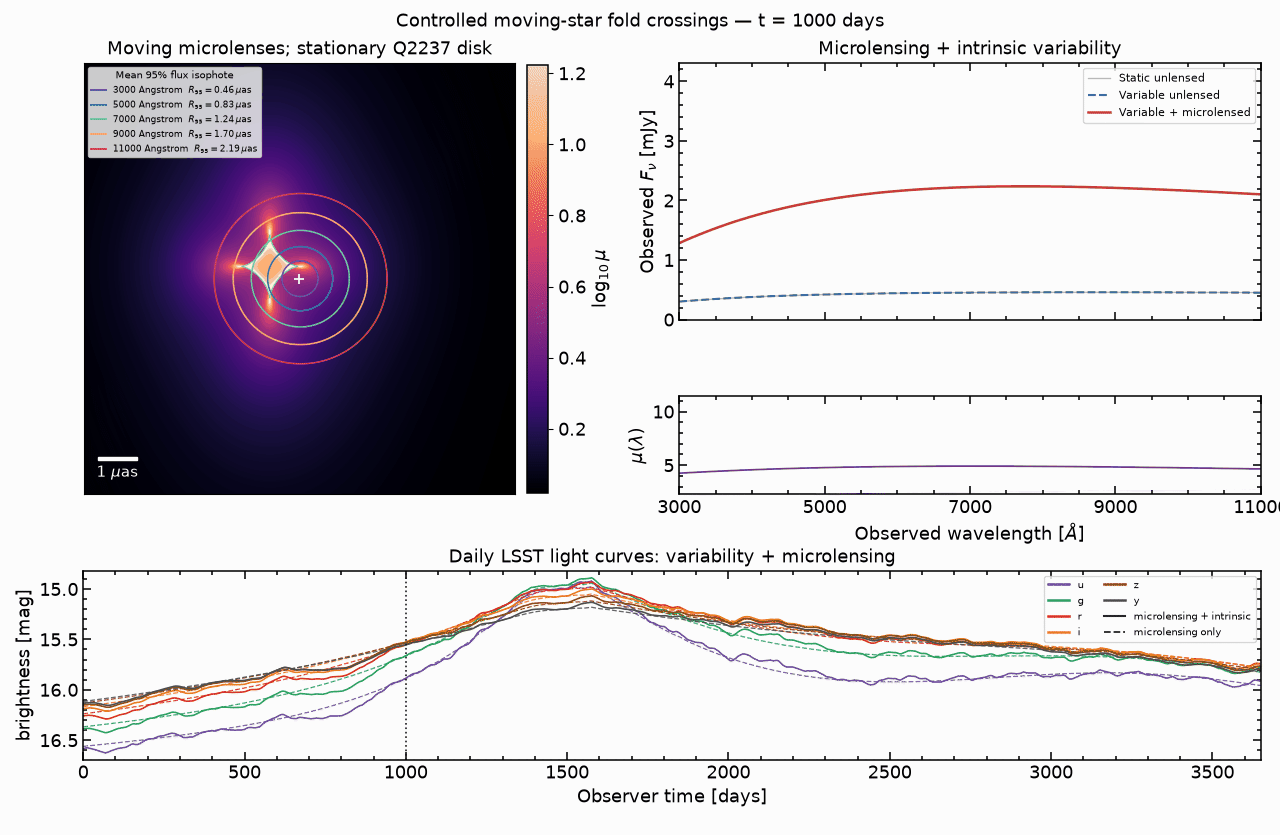

In [7]:
simple_gif_path = render_case(
    "controlled_moving_star",
    "Controlled moving-star fold crossings",
    simple_map_times,
    simple_variable_curve.times_days,
    simple_maps,
    simple_spectra,
    simple_variable_curve,
    simple_static_curve,
    caustics=simple_caustics,
)
print(simple_gif_path.stem.replace("_", " "))
from PIL import Image as PILImage
display(mcp.gif_preview(simple_gif_path, start_frame=40, stop_frame=105))

[View the full GIF](../assets/animations/controlled_moving_star_microlensing_and_variability.gif)

## Q2237+0305 image B: full moving stellar field

This is the physical production-style example. It uses image B's convergence and shear, a Salpeter population with mean mass $0.3\,M_\odot$ and mass ratio 100, stellar dispersion of 170 km/s per component, redshift-scaled peculiar velocities, the CMB dipole, bulk-velocity seed 0, and stellar seed 11. The package derives the complete circular stellar aperture and observer-frame angular velocities.

The source remains fixed at the map center. Every change in the left panel comes from the moving full stellar field. On CUDA the calculation spans ten years: 147 maps at 25-day cadence and 3651 daily source/photometry epochs.

In [8]:
q2237_map_times = torch.arange(
    0.0, Q2237_DURATION_DAYS + 0.5 * MAP_CADENCE_DAYS, MAP_CADENCE_DAYS,
    dtype=torch.float32,
)
q2237_method = mc.production_ipm_config(rays=Q2237_RAYS)
q2237_schedule = mc.production_dynamic_config()
assert q2237_method.rays == 10_000_000
assert q2237_method.scout_ratio == 2
assert q2237_method.refinement == 2
assert q2237_method.virtual_refinement == 4
assert q2237_schedule.temporal_batch_size == 49
assert q2237_schedule.scout_refresh_frames == 10
q2237_variable_curve, q2237_static_curve, q2237_maps, q2237_spectra = run_shared_light_curves(
    q2237_system,
    q2237_map_times,
    q2237_method,
    q2237_schedule,
)

assert float(q2237_variable_curve.times_days[1] - q2237_variable_curve.times_days[0]) == SOURCE_CADENCE_DAYS
assert q2237_maps[0].values.shape == (MAP_RESOLUTION, MAP_RESOLUTION)
print("Q2237 B IPM preset:", q2237_method)
print("Q2237 B dynamic preset:", q2237_schedule)

print("Q2237 B stars:", len(q2237_realization.stars))
print("Q2237 B map epochs:", len(q2237_map_times))
print("Q2237 B daily light-curve epochs:", len(q2237_variable_curve.times_days))
print("Source center is fixed at (0, 0) microarcsec")
report_intrinsic_variability(q2237_variable_curve, q2237_static_curve, "Q2237 B")

C:\Users\fagin\Desktop\microlensing\microcaustics_package\src\microcaustics\lens\models.py:842: CompilationWarning: Compilation event 12: preparing a new torch.compile specialization for specular stellar-boundary evolution on cuda (torch.float32). This first call may be slow while code is compiled or loaded from the compiler cache. Another warning for this component indicates a new specialization or cache miss. Set warn_on_compile=False to suppress these messages.
  positions, _ = run_tensor_kernel(


Q2237 B IPM preset: IPMConfig(rays=10000000, scout_ratio=2, refinement=2, virtual_refinement=4, tiled=True, scout_halo_pixels=0.0, scout_dilation_cells=1, scout_trace_centers=False, dual_scout_scalar_correction=True, cell_chunk_size=524288, compact_sparse_nodes=True, far_field_approx=FarFieldApproxConfig(enabled=True, cells_per_axis=16, nodes_per_cell_axis=8, exact_radius_cells=1.0, taylor_order=4, center_translation_order=10))
Q2237 B dynamic preset: DynamicConfig(temporal_batch_size=49, light_curve_batch_size=None, fused_temporal_ipm=True, scout_refresh_frames=10, tuning=AutoTuningConfig(enabled=False, tune_temporal_batch=True, tune_spatial_chunk=True, temporal_candidates=(1, 4, 8, 12, 16, 20, 24, 32, 40, 49, 64), spatial_candidates=(16384, 32768, 65536, 131072, 262144, 524288, 1048576), warmup_runs=1, benchmark_runs=2, maximum_trial_frames=64, memory_fraction=None, memory_headroom_fraction=0.95, verify_numerics=True, verification_rtol=5e-05, verification_atol=5e-06, cache=True), min

q2237_image_b_full_field microlensing_and_variability:   1/147


q2237_image_b_full_field microlensing_and_variability:  26/147


q2237_image_b_full_field microlensing_and_variability:  51/147


q2237_image_b_full_field microlensing_and_variability:  76/147


q2237_image_b_full_field microlensing_and_variability: 101/147


q2237_image_b_full_field microlensing_and_variability: 126/147


q2237_image_b_full_field microlensing_and_variability: 147/147


q2237 image b full field microlensing and variability



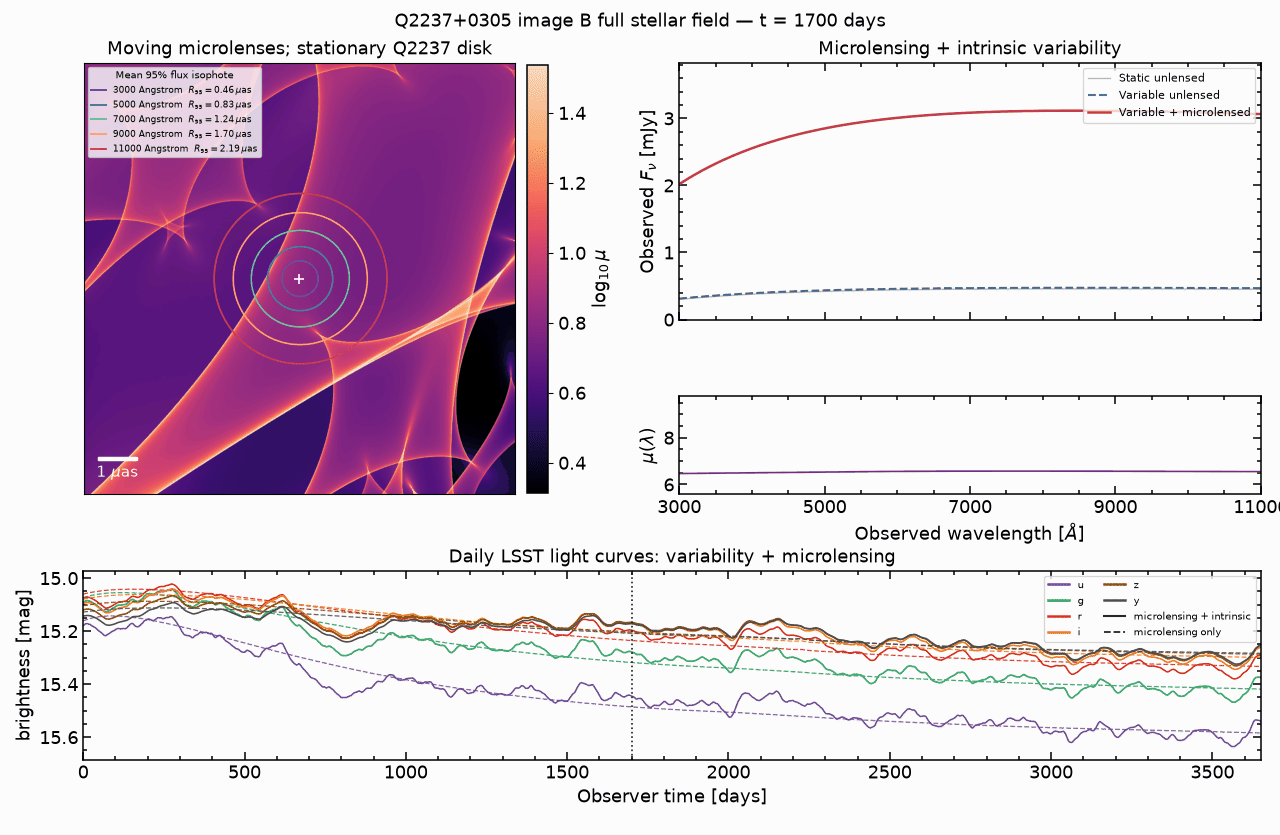

In [9]:
q2237_gif_path = render_case(
    "q2237_image_b_full_field",
    "Q2237+0305 image B full stellar field",
    q2237_map_times,
    q2237_variable_curve.times_days,
    q2237_maps,
    q2237_spectra,
    q2237_variable_curve,
    q2237_static_curve,
)
print(q2237_gif_path.stem.replace("_", " "))
display(mcp.gif_preview(q2237_gif_path, start_frame=68, stop_frame=133))

[View the full GIF](../assets/animations/q2237_image_b_full_field_microlensing_and_variability.gif)

## Reading the result

- The notebook has one production configuration: 3650 observer days, 25-day maps, one-day photometry, 1024-by-1024 magnification maps, and the validated $10^7$-ray production IPM and dynamic presets. There is no automatic CPU downgrade.
- Every wavelength is observed-frame. The spectrum and $\mu(\lambda)$ panels are limited exactly to 3000--11000 Angstrom.
- The disk remains fixed at the origin. Only the microlenses and their caustic fields move.
- Each colored source boundary is measured from the full daily time-average of the corresponding two-dimensional variable Kerr-disk image. It encloses 95% of the mean flux and retains the image's projected shape. The reported $R_{95}$ is only the area-equivalent radius. No circles are plotted.
- In both GIFs the solid curves are microlensing plus intrinsic variability and dashed curves are the microlensing-only baseline, both sampled daily on the same magnitude scale. This follows the comparison used in `04_simulation_datasets`.
- These are continuum predictions. Real spectra additionally contain lines, absorption, extinction, and instrumental bandpasses.
